# Global Music Market & Genre Trends
Robyn Moore · Music analytics portfolio · Spotify Top 200 charts (MGD+) · Python, pandas, scikit-learn

This notebook is the full pipeline behind the [case study](case-study.pdf) and the [aggregate results](aggregate-results.zip): chart loading, de-duplication, the genre-family mapping, and every table and chart. The published findings are in the [project README](README.md).

**Business brief:** How do Top 200 genre tastes vary by market, which genres gain share over time, and which territories merit further testing for an international artist campaign?

**Scope and cautions:** Spotify *Top 200 chart activity* is **not** total market consumption or music-industry revenue. Genre families below are a **custom, rules-based taxonomy**, derived from the *first credited artist* and their Spotify `main_genre`. Results are descriptive/observational, not predictions of campaign success.

### Before running in Google Colab
Upload these files to the **Files** sidebar (normally `/content/`):
1. `regional.zip` — the MGD+ `charts/regional` folder compressed into a ZIP
2. `spotify_hit_songs_dataset_complete.csv`
3. `spotify_artists_info_complete.csv`
4. `spotify_charts_regional_gb.csv` — **required if GB is absent from the ZIP**

Colab's temporary files disappear when the runtime resets, so re-upload or put the files on Google Drive when running in a new session. Then use **Runtime → Run all**. On an initial run, processing the chart files may take several minutes.

## 1. Set up imports and identify the source files
All inputs are checked before any analysis starts. GB is registered by its market code **once**, whether its CSV is in the ZIP or separate.

In [ ]:
from pathlib import Path
import ast
import zipfile

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

ROOT = Path("/content")
ZIP_PATH = ROOT / "regional.zip"
SONGS_PATH = ROOT / "spotify_hit_songs_dataset_complete.csv"
ARTISTS_PATH = ROOT / "spotify_artists_info_complete.csv"
GB_PATH = ROOT / "spotify_charts_regional_gb.csv"
EXTRACT_DIR = ROOT / "regional_charts"
OUTPUT_DIR = ROOT / "project4_outputs"

for path in [ZIP_PATH, SONGS_PATH, ARTISTS_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing input: {path}. Upload it to Colab's Files sidebar first.")

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as archive:
    archive.extractall(EXTRACT_DIR)

# Key by market to prevent accidental duplicate GB loading.
market_files = {}
for path in sorted(EXTRACT_DIR.rglob("spotify_charts_regional_*.csv")):
    market = path.stem.removeprefix("spotify_charts_regional_")
    if market in market_files:
        raise ValueError(f"Duplicate CSV in ZIP for {market}: {path}")
    market_files[market] = path

if "gb" not in market_files:
    if not GB_PATH.is_file():
        raise FileNotFoundError("GB is missing from regional.zip; also upload spotify_charts_regional_gb.csv.")
    market_files["gb"] = GB_PATH

chart_files = [market_files[market] for market in sorted(market_files)]
print("Chart files:", len(chart_files))
print("GB included:", "gb" in market_files)
print("Market codes:", sorted(market_files))

Chart files: 72
GB included: True
Market codes: ['ae', 'ae-checkpoint', 'ar', 'at', 'au', 'be', 'bg', 'bo', 'br', 'ca', 'ch', 'cl', 'co', 'cr', 'cy', 'cy-checkpoint', 'cz', 'de', 'dk', 'do', 'ec', 'ee', 'eg', 'es', 'fi', 'fr', 'gb', 'global', 'gr', 'gt', 'hk', 'hn', 'hu', 'id', 'ie', 'il', 'in', 'is', 'it', 'jp', 'kr', 'kr-checkpoint', 'lt', 'lu', 'lv', 'ma', 'mx', 'my', 'ni', 'nl', 'no', 'nz', 'pa', 'pe', 'ph', 'pl', 'pt', 'py', 'ro', 'ru', 'sa', 'se', 'sg', 'sk', 'sv', 'th', 'tr', 'tw', 'ua', 'us', 'vn', 'za']


## 2. Master song and artist metadata
The chart song ID joins to the full song table; its first credited artist joins to the artist genre table. A single primary genre assignment avoids counting a collaboration's streams multiple times.

In [ ]:
songs = pd.read_csv(SONGS_PATH, sep="\t")
artists = pd.read_csv(ARTISTS_PATH, sep="\t")

assert songs["song_id"].is_unique, "Check duplicate song IDs before joining."
assert artists["artist_id"].is_unique, "Check duplicate artist IDs before joining."

print("Master songs:", songs.shape)
print("Master artists:", artists.shape)
print("Song IDs unique:", songs["song_id"].is_unique)
print("Artist IDs unique:", artists["artist_id"].is_unique)

Master songs: (126213, 24)
Master artists: (91880, 7)
Song IDs unique: True
Artist IDs unique: True


### Genre-family mapping
Original `main_genre` stays available for drill-down. The grouping is intended for cross-market comparison, not as an official Spotify taxonomy. Order matters: Brazilian funk must not be misread as conventional funk, and `g funk` belongs with Hip-Hop/Rap.

In [ ]:
def classify_genre(genre):
    if pd.isna(genre):
        return "Unknown"

    g = genre.lower().strip()

    # Afro
    if any(x in g for x in [
        "afrobeat", "afrobeats", "afroswing", "amapiano"
    ]):
        return "Afro"

    # Hip-Hop / Rap
    elif any(x in g for x in [
        "hip hop", "hip-hop", "rap", "trap", "drill",
        "grime", "boom bap", "phonk", "plugg",
        "g funk", "drain"
    ]):
        return "Hip-Hop / Rap"

    # Brazilian styles
    elif any(x in g for x in [
        "arrocha", "agronejo", "pagode", "forro",
        "forró", "arrochadeira", "deboxe",
        "mpb", "bossa nova", "manguebeat",
        "sertanejo", "samba", "brazilian gospel",
        "funk carioca", "funk bh", "funk mandelao",
        "funk mandelão", "funk mtg", "funk 150 bpm",
        "funk pop", "funk consciente", "funk rj",
        "funk paulista", "brega funk",
        "funk viral", "rave funk"
    ]):
        return "Brazilian"

    # Filipino
    elif "opm" in g:
        return "Filipino / OPM"

    # MENA
    elif any(x in g for x in [
        "khaliji", "khaleeji", "sheilat", "jalsat",
        "mahraganat", "rai", "arabesk",
        "israeli mediterranean"
    ]):
        return "MENA"

    # South Asian film music
    elif any(x in g for x in [
        "filmi", "bollywood", "tollywood"
    ]):
        return "South Asian / Film"

    # Latin + regional Latin styles
    elif any(x in g for x in [
        "latin", "reggaeton", "urbano", "bachata",
        "salsa", "cumbia", "banda", "corrido",
        "mariachi", "musica mexicana", "regional mexican",
        "bolero", "grupera", "huapango", "sierreno",
        "sierreño", "tex-mex", "dembow", "cubaton",
        "neoperreo", "mambo chileno", "cuarteto",
        "ranchera", "norteno", "norteño", "vallenato",
        "merengue"
    ]):
        return "Latin"

    elif any(x in g for x in ["r&b", "soul", "motown"]):
        return "R&B / Soul"

    elif any(x in g for x in [
        "reggae", "dancehall", "basshall"
    ]):
        return "Reggae / Dancehall"

    elif any(x in g for x in [
        "country", "folk", "americana",
        "bluegrass", "singer-songwriter"
    ]):
        return "Country / Folk"

    elif any(x in g for x in [
        "metal", "punk", "hardcore"
    ]):
        return "Metal / Punk"

    elif any(x in g for x in [
        "rock", "alternative", "indie", "grunge",
        "britpop", "beatlesque", "permanent wave",
        "new romantic", "psych", "emo", "dreamo"
    ]):
        return "Rock / Alternative"

    # Do NOT use generic substring "funk" here
    elif (
        "jazz" in g
        or "blues" in g
        or g == "funk"
        or g == "jazz funk"
    ):
        return "Jazz / Blues / Funk"

    elif any(x in g for x in [
        "classical", "opera", "orchestra"
    ]):
        return "Classical"

    elif any(x in g for x in [
        "anime", "otacore", "hollywood", "broadway",
        "show tunes", "movie tunes", "soundtrack", "musical"
    ]):
        return "Soundtrack / Anime"

    # Pop before electronic because "dance pop" should remain Pop
    elif any(x in g for x in [
        "pop", "alt z", "girl group", "boy band",
        "talent show", "adult standards", "neo mellow",
        "concurso de talentos"
    ]):
        return "Pop"

    elif any(x in g for x in [
        "edm", "house", "techno", "trance", "dubstep",
        "electronic", "electronica", "dance", "brostep",
        "big room", "complextro", "disco",
        "aussietronica", "melbourne bounce",
        "glitchcore"
    ]):
        return "Electronic / Dance"

    else:
        return "Other"

In [ ]:
songs["artist_id_list"] = songs["artist_id"].apply(ast.literal_eval)
songs["primary_artist_id"] = songs["artist_id_list"].str[0]

song_lookup = songs[["song_id", "primary_artist_id"]].merge(
    artists[["artist_id", "main_genre"]],
    left_on="primary_artist_id",
    right_on="artist_id",
    how="left",
    validate="many_to_one"
)
song_lookup["genre_family"] = song_lookup["main_genre"].apply(classify_genre)
song_lookup = song_lookup[[
    "song_id", "primary_artist_id", "main_genre", "genre_family"
]]
assert song_lookup["song_id"].is_unique

print("Master genre lookup:", song_lookup.shape)
print(f"Songs with main_genre: {song_lookup['main_genre'].notna().mean():.2%}")
print("Taxonomy spot checks:", [classify_genre(g) for g in
      ["british soul", "bedroom soul", "brazilian gospel", "funk carioca", "g funk"]])

Master genre lookup: (126213, 4)
Songs with main_genre: 92.55%
Taxonomy spot checks: ['R&B / Soul', 'R&B / Soul', 'Brazilian', 'Brazilian', 'Hip-Hop / Rap']


## 3. Audit, deduplicate and aggregate every market
Each market is loaded separately to limit memory use. First remove exact duplicate records; then retain a single `market + Date + Position + ID` observation to handle text/metadata variants of the same chart placement. One empty file, Cyprus (`cy`), is documented rather than silently dropped.

**Output grain:** one row per **market × month × genre family**. `unique_songs` is unique *within that group*, not a total to sum across months.

In [ ]:
global_parts = []
quality_rows = []

for market_code, file in sorted(market_files.items()):
    # Skip Colab checkpoint files
    if "checkpoint" in market_code or ".ipynb_checkpoints" in str(file):
        continue

    df = pd.read_csv(file, sep="\t")
    rows_before = len(df)

    if df.empty:
        quality_rows.append({
            "market": market_code, "raw_rows": 0, "clean_rows": 0,
            "exact_duplicates_removed": 0, "key_duplicates_removed": 0,
            "rows_removed": 0, "unmatched_song_rows": 0,
            "unknown_genre_rows": 0, "bad_days_after_cleaning": 0,
            "first_date": pd.NaT, "last_date": pd.NaT
        })
        continue

    df["Date"] = pd.to_datetime(df["Date"])
    if not df["market"].eq(market_code).all():
        raise ValueError(f"Market code mismatch in {file}")

    first_date, last_date = df["Date"].min(), df["Date"].max()
    df = df.drop_duplicates()
    exact_removed = rows_before - len(df)

    before_key = len(df)
    df = df.drop_duplicates(subset=["market", "Date", "Position", "ID"], keep="first")
    key_removed = before_key - len(df)
    clean_rows = len(df)

    bad_days = int((df.groupby("Date").size() > 200).sum())
    if bad_days:
        raise ValueError(f"{market_code}: some dates still have over 200 chart rows")

    df["Streams"] = pd.to_numeric(
        df["Streams"].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )
    df = df.merge(
        song_lookup,
        left_on="ID", right_on="song_id",
        how="left", validate="many_to_one", indicator="song_match"
    )
    unmatched = int((df["song_match"] != "both").sum())
    # Keep unmatched chart placements visible in Unknown rather than silently losing them.
    df["genre_family"] = df["genre_family"].fillna("Unknown")
    unknown = int((df["genre_family"] == "Unknown").sum())
    df["month"] = df["Date"].dt.to_period("M").dt.to_timestamp()

    monthly = (
        df.groupby(["market", "month", "genre_family"], as_index=False)
        .agg(streams=("Streams", "sum"),
             chart_rows=("ID", "size"),
             unique_songs=("ID", "nunique"))
    )
    global_parts.append(monthly)
    quality_rows.append({
        "market": market_code, "raw_rows": rows_before, "clean_rows": clean_rows,
        "exact_duplicates_removed": exact_removed,
        "key_duplicates_removed": key_removed,
        "rows_removed": rows_before - clean_rows,
        "unmatched_song_rows": unmatched,
        "unknown_genre_rows": unknown,
        "bad_days_after_cleaning": bad_days,
        "first_date": first_date, "last_date": last_date
    })

quality_log = pd.DataFrame(quality_rows).sort_values("market").reset_index(drop=True)
global_genre_monthly = pd.concat(global_parts, ignore_index=True)

print("Monthly genre table:", global_genre_monthly.shape)
print("Markets with data (including 'global'):", global_genre_monthly["market"].nunique())
print("Total chart rows read:", f"{quality_log['raw_rows'].sum():,}")
print("Duplicates removed:", f"{quality_log['rows_removed'].sum():,}")
print("Unmatched chart rows:", f"{quality_log['unmatched_song_rows'].sum():,}")
print("Unknown genre chart rows:", f"{quality_log['unknown_genre_rows'].sum()/quality_log['clean_rows'].sum():.2%}")
print("Empty market files:", quality_log.loc[quality_log["raw_rows"] == 0, "market"].tolist())

display(quality_log.loc[quality_log["rows_removed"] > 0,
                        ["market", "exact_duplicates_removed", "key_duplicates_removed", "rows_removed"]])
assert quality_log["unmatched_song_rows"].sum() == 0, "Inspect unmatched songs before using results."

Monthly genre table: (39380, 6)
Markets with data (including 'global'): 68
Total chart rows read: 21,257,472
Duplicates removed: 2,000
Unmatched chart rows: 0
Unknown genre chart rows: 1.54%
Empty market files: ['cy']


,market,exact_duplicates_removed,key_duplicates_removed,rows_removed
3,au,198,2,200
7,br,194,6,200
8,ca,196,4,200
15,de,194,6,200
23,fr,198,2,200
24,gb,198,2,200
25,global,196,4,200
37,jp,192,8,200
46,nl,195,5,200
66,us,196,4,200


## 4. BQ1 — Which genres over-index in specific markets?
The 2021 comparison sample includes **non-global markets with all 12 recorded months**. The benchmark is an **equal-weight mean of within-market genre shares**, treating absent genres as 0 rather than dropping those markets. `Unknown` and `Other` are excluded from the interpretable-genre denominator.

In [ ]:
coverage_2021 = (
    global_genre_monthly.loc[
        (global_genre_monthly["month"].dt.year == 2021)
        & (global_genre_monthly["market"] != "global")
    ]
    .groupby("market", as_index=False)
    .agg(months_covered=("month", "nunique"))
)
complete_markets = sorted(coverage_2021.loc[
    coverage_2021["months_covered"] == 12, "market"
].tolist())

analysis_2021 = global_genre_monthly.loc[
    (global_genre_monthly["month"].dt.year == 2021)
    & (global_genre_monthly["market"].isin(complete_markets))
    & (~global_genre_monthly["genre_family"].isin(["Unknown", "Other"]))
].copy()

print("Complete 2021 non-global markets:", len(complete_markets))
print("Excluded/incomplete:")
display(coverage_2021.loc[coverage_2021["months_covered"] < 12])

market_genre = (
    analysis_2021.groupby(["market", "genre_family"], as_index=False)
    .agg(streams=("streams", "sum"))
)
# Explicit zero-genre rows make each market count equally in the benchmark.
full_index = pd.MultiIndex.from_product(
    [complete_markets, sorted(analysis_2021["genre_family"].unique())],
    names=["market", "genre_family"]
)
market_genre = (
    market_genre.set_index(["market", "genre_family"])
    .reindex(full_index, fill_value=0).reset_index()
)
market_totals = market_genre.groupby("market", as_index=False).agg(
    market_streams=("streams", "sum")
)
market_genre = market_genre.merge(market_totals, on="market", validate="many_to_one")
market_genre["genre_share"] = market_genre["streams"] / market_genre["market_streams"]

benchmark = market_genre.groupby("genre_family", as_index=False).agg(
    avg_market_share=("genre_share", "mean")
)
market_genre = market_genre.merge(benchmark, on="genre_family", validate="many_to_one")
market_genre["over_index"] = market_genre["genre_share"] / market_genre["avg_market_share"]

assert "gb" in complete_markets, "GB must appear in the complete 2021 comparison."
assert market_genre.groupby("market")["genre_share"].sum().sub(1).abs().max() < 1e-9

Complete 2021 non-global markets: 65
Excluded/incomplete:


,market,months_covered
36,kr,11
38,lu,9


In [ ]:
top_overindex = (
    market_genre.loc[market_genre["genre_share"] >= 0.05,
                     ["market", "genre_family", "genre_share", "over_index"]]
    .sort_values("over_index", ascending=False)
    .head(30).copy()
)
top_overindex["genre_share_pct"] = (100 * top_overindex["genre_share"]).round(2)
display(top_overindex[["market", "genre_family", "genre_share_pct", "over_index"]].round(2))

top_markets_by_genre = (
    market_genre.loc[market_genre["genre_share"] >= 0.03]
    .sort_values(["genre_family", "over_index"], ascending=[True, False])
    .groupby("genre_family").head(3).copy()
)
top_markets_by_genre["genre_share_pct"] = (top_markets_by_genre["genre_share"] * 100).round(2)
print("Top market affinities for each genre (min. 3% share):")
display(top_markets_by_genre[["genre_family", "market", "genre_share_pct", "over_index"]].round(2))

,market,genre_family,genre_share_pct,over_index
560,in,South Asian / Film,6.14,64.01
804,ph,Filipino / OPM,25.29,63.20
1088,za,Afro,20.19,59.59
120,br,Brazilian,77.37,51.37
610,jp,Soundtrack / Anime,18.44,43.95
761,nz,Reggae / Dancehall,5.44,28.83
910,sa,MENA,27.31,25.42
536,il,MENA,20.44,19.03
332,eg,MENA,12.65,11.77
564,is,Country / Folk,9.98,10.90


Top market affinities for each genre (min. 3% share):


,genre_family,market,genre_share_pct,over_index
1088,Afro,za,20.19,59.59
120,Brazilian,br,77.37,51.37
834,Brazilian,pt,14.65,9.73
851,Brazilian,py,3.91,2.59
564,Country / Folk,is,9.98,10.90
1057,Country / Folk,us,5.32,5.82
139,Country / Folk,ca,5.05,5.51
718,Electronic / Dance,nl,13.14,3.39
480,Electronic / Dance,hu,12.59,3.24
72,Electronic / Dance,be,12.26,3.16


## 5. BQ2 — How did genre share change, 2018–2021?
To avoid shifts in country coverage contaminating the trend, use only markets observed in **all 48 months** from January 2018 to December 2021. For each year, calculate genre share *within each market*, then average those shares equally across markets. Change is reported in **percentage points**, not relative percent.

In [ ]:
trend_coverage = (
    global_genre_monthly.loc[
        (global_genre_monthly["market"] != "global")
        & global_genre_monthly["month"].between("2018-01-01", "2021-12-01")
    ]
    .groupby("market", as_index=False)
    .agg(months_covered=("month", "nunique"))
)
trend_markets = sorted(trend_coverage.loc[
    trend_coverage["months_covered"] == 48, "market"
].tolist())
print("Balanced 2018–2021 markets:", len(trend_markets))

trend_data = global_genre_monthly.loc[
    global_genre_monthly["market"].isin(trend_markets)
    & global_genre_monthly["month"].between("2018-01-01", "2021-12-01")
    & (~global_genre_monthly["genre_family"].isin(["Unknown", "Other"]))
].copy()
trend_data["year"] = trend_data["month"].dt.year

market_year_genre = (
    trend_data.groupby(["market", "year", "genre_family"], as_index=False)
    .agg(streams=("streams", "sum"))
)
all_years = [2018, 2019, 2020, 2021]
full_trend_index = pd.MultiIndex.from_product(
    [trend_markets, all_years, sorted(trend_data["genre_family"].unique())],
    names=["market", "year", "genre_family"]
)
market_year_genre = (
    market_year_genre.set_index(["market", "year", "genre_family"])
    .reindex(full_trend_index, fill_value=0).reset_index()
)
market_year_totals = market_year_genre.groupby(["market", "year"], as_index=False).agg(
    total_streams=("streams", "sum")
)
market_year_genre = market_year_genre.merge(
    market_year_totals, on=["market", "year"], validate="many_to_one"
)
market_year_genre["genre_share"] = (
    market_year_genre["streams"] / market_year_genre["total_streams"]
)
assert market_year_genre.groupby(["market", "year"])["genre_share"].sum().sub(1).abs().max() < 1e-9

Balanced 2018–2021 markets: 52


In [ ]:
genre_trend = (
    market_year_genre.groupby(["year", "genre_family"], as_index=False)
    .agg(avg_market_share=("genre_share", "mean"))
)
genre_trend["share_pct"] = genre_trend["avg_market_share"] * 100
trend_change = genre_trend.pivot(index="genre_family", columns="year", values="share_pct").reset_index()
trend_change["change_2018_2021_pp"] = trend_change[2021] - trend_change[2018]
trend_change = trend_change.sort_values("change_2018_2021_pp", ascending=False)
display(trend_change.round(2))

year,genre_family,2018,2019,2020,2021,change_2018_2021_pp
12,R&B / Soul,0.96,1.69,3.65,3.69,2.73
14,Rock / Alternative,4.09,4.10,3.23,6.66,2.57
8,Latin,13.32,14.01,15.41,15.36,2.05
3,Country / Folk,0.84,0.89,0.84,1.07,0.23
11,Pop,40.65,43.39,40.75,40.86,0.21
10,Metal / Punk,0.15,0.24,0.14,0.23,0.09
9,MENA,0.03,0.02,0.03,0.06,0.04
7,Jazz / Blues / Funk,0.09,0.10,0.16,0.12,0.02
16,South Asian / Film,0.00,0.00,0.00,0.00,0.00
2,Classical,0.00,0.00,0.00,0.00,0.00


## 6. BQ3 — Which market–genre combinations have scale **and** momentum?
Filter for genres at **≥5% of the 2021 market's known-category charted streams** and **≥+2 percentage points from 2018**. These are screening criteria, not statistical significance or guaranteed commercial opportunities.

In [ ]:
market_genre_change = (
    market_year_genre.loc[market_year_genre["year"].isin([2018, 2021])]
    .pivot(index=["market", "genre_family"], columns="year", values="genre_share")
    .reset_index()
)
market_genre_change["share_2018_pct"] = market_genre_change[2018] * 100
market_genre_change["share_2021_pct"] = market_genre_change[2021] * 100
market_genre_change["change_pp"] = (
    market_genre_change["share_2021_pct"] - market_genre_change["share_2018_pct"]
)
opportunity = market_genre_change.merge(
    market_genre[["market", "genre_family", "over_index"]],
    on=["market", "genre_family"], how="left", validate="many_to_one"
)
growth_opportunities = (
    opportunity.loc[(opportunity["share_2021_pct"] >= 5)
                    & (opportunity["change_pp"] >= 2)]
    .sort_values(["change_pp", "share_2021_pct"], ascending=False)
    .copy()
)
display(growth_opportunities[[
    "market", "genre_family", "share_2018_pct", "share_2021_pct",
    "change_pp", "over_index"
]].head(30).round(2))

,market,genre_family,share_2018_pct,share_2021_pct,change_pp,over_index
363,gr,Hip-Hop / Rap,42.58,75.26,32.68,2.76
703,pl,Hip-Hop / Rap,44.43,66.58,22.15,2.45
382,gt,Latin,44.36,61.16,16.80,4.62
830,th,Rock / Alternative,8.27,24.37,16.10,3.63
416,hn,Latin,42.83,57.74,14.90,4.36
193,cz,Hip-Hop / Rap,26.13,40.65,14.53,1.49
178,cr,Latin,33.04,47.39,14.35,3.58
402,hk,Pop,75.17,89.39,14.21,2.24
161,co,Latin,36.85,51.04,14.19,3.85
807,sv,Latin,40.20,54.37,14.16,4.11


## 7. BQ4 — Which genres travel broadly versus remaining localized?
For each genre, count markets where it reaches ≥1% and ≥5% of the known-genre mix. These are **chart-penetration indicators**; they do not trace how individual songs spread or establish causality. Labels Global / Regional / Localized are rule-based portfolio categories.

In [ ]:
genre_reach = (
    market_genre.groupby("genre_family", as_index=False)
    .agg(avg_market_share=("genre_share", "mean"),
         median_market_share=("genre_share", "median"),
         max_market_share=("genre_share", "max"),
         markets_above_1pct=("genre_share", lambda x: (x >= 0.01).sum()),
         markets_above_5pct=("genre_share", lambda x: (x >= 0.05).sum()))
)
for old_col, new_col in [
    ("avg_market_share", "avg_market_share_pct"),
    ("median_market_share", "median_market_share_pct"),
    ("max_market_share", "max_market_share_pct")
]:
    genre_reach[new_col] = genre_reach[old_col] * 100

def reach_category(row):
    if row["markets_above_1pct"] >= 40 and row["markets_above_5pct"] >= 10:
        return "Global"
    elif row["markets_above_1pct"] >= 10 or row["markets_above_5pct"] >= 3:
        return "Regional"
    else:
        return "Localized"

genre_reach["reach_category"] = genre_reach.apply(reach_category, axis=1)
genre_reach = genre_reach.sort_values(
    ["markets_above_5pct", "markets_above_1pct"], ascending=False
)
display(genre_reach[[
    "genre_family", "avg_market_share_pct", "median_market_share_pct",
    "max_market_share_pct", "markets_above_1pct", "markets_above_5pct", "reach_category"
]].round(2))

,genre_family,avg_market_share_pct,median_market_share_pct,max_market_share_pct,markets_above_1pct,markets_above_5pct,reach_category
11,Pop,39.90,35.90,89.39,65,65,Global
6,Hip-Hop / Rap,27.22,23.23,75.32,65,60,Global
14,Rock / Alternative,6.72,5.71,24.37,63,37,Global
4,Electronic / Dance,3.88,3.07,13.14,45,20,Global
8,Latin,13.24,0.48,61.16,23,16,Regional
12,R&B / Soul,3.78,3.21,10.11,64,15,Global
3,Country / Folk,0.92,0.18,9.98,17,3,Regional
9,MENA,1.07,0.01,27.31,6,3,Regional
1,Brazilian,1.51,0.00,77.37,4,2,Localized
15,Soundtrack / Anime,0.42,0.06,18.44,3,1,Localized


## 8. BQ5 — Which markets have similar genre profiles?
K-Means clusters markets using their 2021 genre-share vectors. Shares are already comparable proportions, so **we do not standardize** them; standardization would magnify very rare categories. Test k=2…8 by silhouette, then inspect the interpretability of k=5. Cluster numbers are arbitrary labels, not rankings.

In [ ]:
market_profile = (
    market_genre.pivot(index="market", columns="genre_family", values="genre_share")
    .fillna(0).sort_index()
)
print("Market × genre matrix:", market_profile.shape)
assert "gb" in market_profile.index

cluster_results = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(market_profile)
    cluster_results.append({
        "k": k,
        "silhouette_score": silhouette_score(market_profile, labels)
    })
cluster_results = pd.DataFrame(cluster_results)
display(cluster_results.sort_values("silhouette_score", ascending=False).round(4))

Market × genre matrix: (65, 17)


,k,silhouette_score
0,2,0.5303
3,5,0.5215
2,4,0.4992
5,7,0.4947
4,6,0.4871
1,3,0.4788
6,8,0.4205


In [ ]:
def inspect_clusters(k):
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(market_profile)
    result = market_profile.copy()
    result["cluster"] = labels
    print(f"\nK={k}; sizes:")
    print(result["cluster"].value_counts().sort_index())
    for cluster in sorted(result["cluster"].unique()):
        markets = result.index[result["cluster"] == cluster].tolist()
        print(f"Cluster {cluster}: {markets}")
    return result, model

clusters_2, model_2 = inspect_clusters(2)
clusters_5, model_5 = inspect_clusters(5)

cluster_profiles = clusters_5.groupby("cluster").mean().T * 100
print("\nAverage genre share (%) by k=5 cluster:")
display(cluster_profiles.round(2))

print("\nTop 5 genres in each k=5 cluster:")
for cluster in sorted(clusters_5["cluster"].unique()):
    p = cluster_profiles[cluster].sort_values(ascending=False).head(5)
    print(f"Cluster {cluster}: " + "; ".join(f"{genre} {share:.2f}%" for genre, share in p.items()))


K=2; sizes:
cluster
0    49
1    16
Name: count, dtype: int64
Cluster 0: ['ae', 'at', 'au', 'be', 'bg', 'br', 'ca', 'ch', 'cz', 'de', 'dk', 'ee', 'eg', 'fi', 'fr', 'gb', 'gr', 'hk', 'hu', 'id', 'ie', 'il', 'in', 'is', 'it', 'jp', 'lt', 'lv', 'ma', 'my', 'nl', 'no', 'nz', 'ph', 'pl', 'pt', 'ro', 'ru', 'sa', 'se', 'sg', 'sk', 'th', 'tr', 'tw', 'ua', 'us', 'vn', 'za']
Cluster 1: ['ar', 'bo', 'cl', 'co', 'cr', 'do', 'ec', 'es', 'gt', 'hn', 'mx', 'ni', 'pa', 'pe', 'py', 'sv']

K=5; sizes:
cluster
0    10
1    29
2    16
3     9
4     1
Name: count, dtype: int64
Cluster 0: ['hk', 'id', 'in', 'jp', 'my', 'ph', 'sg', 'th', 'tw', 'vn']
Cluster 1: ['ae', 'at', 'au', 'be', 'bg', 'ca', 'ch', 'cz', 'dk', 'ee', 'fi', 'gb', 'hu', 'ie', 'il', 'is', 'it', 'lt', 'lv', 'nl', 'no', 'nz', 'pt', 'ro', 'sa', 'se', 'tr', 'us', 'za']
Cluster 2: ['ar', 'bo', 'cl', 'co', 'cr', 'do', 'ec', 'es', 'gt', 'hn', 'mx', 'ni', 'pa', 'pe', 'py', 'sv']
Cluster 3: ['de', 'eg', 'fr', 'gr', 'ma', 'pl', 'ru', 'sk', 'ua']
Clus

cluster,0,1,2,3,4
genre_family,,,,,
Afro,0.01,0.75,0.00,0.03,0.00
Brazilian,0.00,0.57,0.25,0.00,77.37
Classical,0.00,0.00,0.00,0.00,0.00
Country / Folk,1.31,1.55,0.03,0.07,0.23
Electronic / Dance,1.47,6.38,0.45,4.87,1.58
Filipino / OPM,2.54,0.02,0.00,0.00,0.00
Hip-Hop / Rap,7.90,31.71,11.86,63.69,7.70
Jazz / Blues / Funk,0.47,0.05,0.00,0.01,0.00
Latin,0.05,0.80,52.04,0.47,0.00



Top 5 genres in each k=5 cluster:
Cluster 0: Pop 69.84%; Rock / Alternative 8.04%; Hip-Hop / Rap 7.90%; R&B / Soul 5.20%; Filipino / OPM 2.54%
Cluster 1: Pop 41.81%; Hip-Hop / Rap 31.71%; Rock / Alternative 9.23%; Electronic / Dance 6.38%; R&B / Soul 4.60%
Cluster 2: Latin 52.04%; Pop 30.36%; Hip-Hop / Rap 11.86%; Rock / Alternative 2.61%; R&B / Soul 2.27%
Cluster 3: Hip-Hop / Rap 63.69%; Pop 20.80%; Rock / Alternative 5.10%; Electronic / Dance 4.87%; R&B / Soul 2.42%
Cluster 4: Brazilian 77.37%; Pop 9.72%; Hip-Hop / Rap 7.70%; R&B / Soul 2.33%; Electronic / Dance 1.58%


## 9. BQ6 — Which international markets might be worth testing?
Compute **cosine similarity** between markets' 2021 genre-share vectors. A potential destination also needs at least a user-set genre share (default 3%; examples below use 5%). The function ranks **primarily by overall profile similarity**, with genre share as a tie-breaker; it is a **candidate shortlist**, not a forecast or a definitive best-to-worst investment ranking.

In [ ]:
similarity_matrix = cosine_similarity(market_profile)
market_similarity = pd.DataFrame(
    similarity_matrix, index=market_profile.index, columns=market_profile.index
)

def most_similar_markets(market, n=5):
    market = market.lower()
    if market not in market_similarity.columns:
        raise ValueError(f"Unknown source market: {market}")
    scores = market_similarity[market].drop(market).sort_values(ascending=False).head(n)
    return pd.DataFrame({"market": scores.index, "similarity": scores.values})

print("Markets with the most similar genre mixes to Great Britain:")
display(most_similar_markets("gb", 10).round(4))

Markets with the most similar genre mixes to Great Britain:


,market,similarity
0,ee,0.9965
1,au,0.9932
2,bg,0.9931
3,be,0.9902
4,nl,0.9834
5,ae,0.9829
6,ca,0.9819
7,lt,0.9813
8,ch,0.9793
9,nz,0.9782


In [ ]:
def international_test_markets(source_market, genre, n=10, min_genre_share=0.03):
    source_market = source_market.lower()
    if source_market not in market_similarity.columns:
        raise ValueError(f"Unknown source market: {source_market}")
    if genre not in market_genre["genre_family"].unique():
        raise ValueError(f"Unknown genre family: {genre}")

    similarity = (market_similarity[source_market].drop(source_market)
                  .rename("similarity").rename_axis("market").reset_index())
    genre_fit = market_genre.loc[
        market_genre["genre_family"] == genre,
        ["market", "genre_share", "over_index"]
    ]
    candidates = similarity.merge(genre_fit, on="market", validate="one_to_one")
    candidates = candidates.loc[candidates["genre_share"] >= min_genre_share].copy()
    candidates = candidates.sort_values(["similarity", "genre_share"], ascending=False)
    candidates["genre_share_pct"] = candidates["genre_share"] * 100
    return candidates[["market", "similarity", "genre_share_pct", "over_index"]].head(n).round(3)

print("UK Rock / Alternative: candidate international test markets")
rock_tests = international_test_markets("gb", "Rock / Alternative", n=10, min_genre_share=0.05)
display(rock_tests)

print("UK Electronic / Dance: candidate international test markets")
electronic_tests = international_test_markets("gb", "Electronic / Dance", n=10, min_genre_share=0.05)
display(electronic_tests)

UK Rock / Alternative: candidate international test markets


,market,similarity,genre_share_pct,over_index
18,ee,0.997,12.889,1.918
3,au,0.993,12.084,1.799
5,bg,0.993,10.344,1.540
4,be,0.990,10.656,1.586
41,nl,0.983,7.674,1.142
0,ae,0.983,6.353,0.946
8,ca,0.982,8.141,1.212
35,lt,0.981,19.393,2.886
9,ch,0.979,7.766,1.156
43,nz,0.978,12.192,1.815


UK Electronic / Dance: candidate international test markets


,market,similarity,genre_share_pct,over_index
18,ee,0.997,8.716,2.245
3,au,0.993,5.086,1.310
4,be,0.990,12.260,3.158
41,nl,0.983,13.143,3.385
35,lt,0.981,8.075,2.080
9,ch,0.979,11.474,2.955
27,hu,0.975,12.591,3.243
36,lv,0.972,7.783,2.005
13,cz,0.971,7.694,1.982
53,se,0.971,5.955,1.534


## 10. Export the portfolio-ready tables
This saves lightweight aggregate tables and the data-quality audit. The large source CSVs are **not** included in the exported files. To take these results to another tool, download files from `/content/project4_outputs/` after running the notebook.

In [ ]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
exports = {
    "01_data_quality_by_market.csv": quality_log,
    "02_global_market_month_genre.csv": global_genre_monthly,
    "03_market_genre_share_2021.csv": market_genre,
    "04_top_market_affinities_2021.csv": top_markets_by_genre,
    "05_genre_trends_2018_2021.csv": trend_change,
    "06_market_genre_growth_opportunities.csv": growth_opportunities,
    "07_genre_international_reach.csv": genre_reach,
    "08_market_clusters_k5.csv": clusters_5.reset_index(),
    "09_uk_rock_test_markets.csv": rock_tests,
    "10_uk_electronic_test_markets.csv": electronic_tests,
}
for filename, table in exports.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)
print(f"Saved {len(exports)} result files to {OUTPUT_DIR}")
print("Note: results are from historical Spotify Top 200 charts, not total market consumption.")

Saved 10 result files to /content/project4_outputs
Note: results are from historical Spotify Top 200 charts, not total market consumption.


## Methodology and limitations for the final case study
- **Provenance:** MGD+ Spotify regional Top 200 chart files plus complete song and artist metadata; source date range determined by the files.
- **Duplicate policy:** Exact duplicates first; then one market/date/chart-rank/song ID observation. Preserve text metadata in the source files.
- **Genre definition:** Assign one family using the first credited artist's main genre; collaboration and multi-genre nuance is lost by design. Broad families rely on documented keywords; not an official Spotify classification.
- **Samples:** Compare markets with all 12 observed months in 2021; trends use only markets with all 48 months from 2018–2021. *Presence in a month does not establish that every day was reported*.
- **Denominators:** `Unknown` and `Other` are excluded from interpretable genre-share results. They remain in the data-quality logs and aggregated table.
- **Benchmarks:** Equal weight per market; absent genres get zero share. This measures the typical market rather than aggregate global Spotify listening.
- **Clustering:** K-Means on unscaled genre share vectors; k=2…8 silhouette comparisons; k=5 is used for business interpretability, with possible singleton markets.
- **Target-market shortlists:** Similarity and local genre strength are exploratory screening signals. Verify artists, songs, language, playlists, audience, competition, marketing costs, and contemporary performance before making budget decisions.

**Next portfolio step:** visualize the approved tables, present several market examples, and connect recommendations to a label's test-and-learn marketing plan.

## 11. Charts for the case study
Each chart reads one of the exported tables and saves a figure beside them. Country codes are mapped to names for the labels.

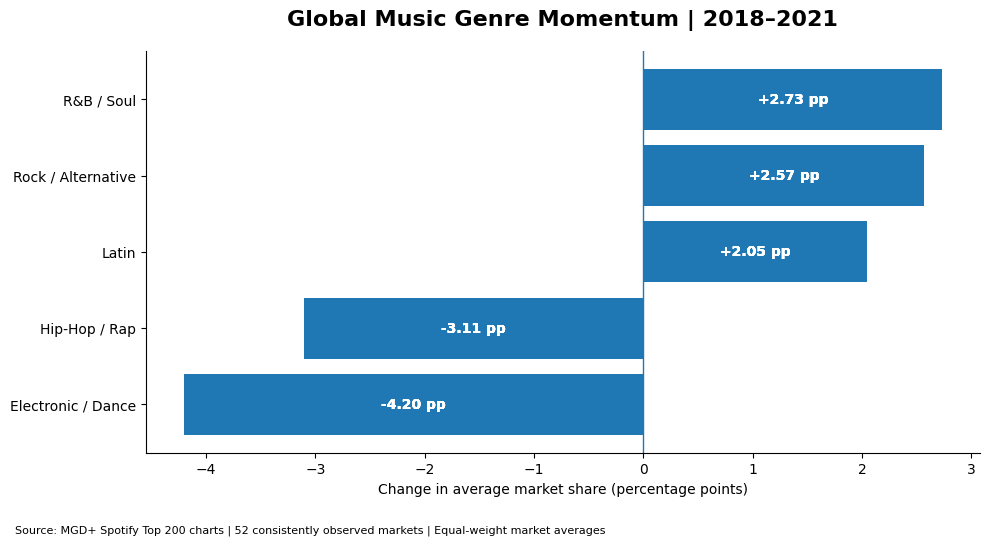

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the finalized genre trend results
trends = pd.read_csv(
    "/content/project4_outputs/05_genre_trends_2018_2021.csv"
)

# Select the three largest gainers and two largest decliners
top_gainers = trends.nlargest(3, "change_2018_2021_pp")
top_decliners = trends.nsmallest(2, "change_2018_2021_pp")

chart_data = pd.concat(
    [top_gainers, top_decliners]
).sort_values("change_2018_2021_pp")

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    chart_data["genre_family"],
    chart_data["change_2018_2021_pp"]
)

# Add the zero reference line
ax.axvline(0, linewidth=1)

# Add readable values
for bar, value in zip(
    bars, chart_data["change_2018_2021_pp"]
):
    # Put values inside the bars
    ax.bar_label(
        bars,
        labels=[
            f"{value:+.2f} pp"
            for value in chart_data["change_2018_2021_pp"]
        ],
        label_type="center",
        color="white",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title(
    "Global Music Genre Momentum | 2018–2021",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Change in average market share (percentage points)"
)
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.02, 0.02,
    "Source: MGD+ Spotify Top 200 charts | "
    "52 consistently observed markets | "
    "Equal-weight market averages",
    fontsize=8
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

plt.savefig(
    "/content/project4_outputs/Figure_01_Genre_Momentum.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

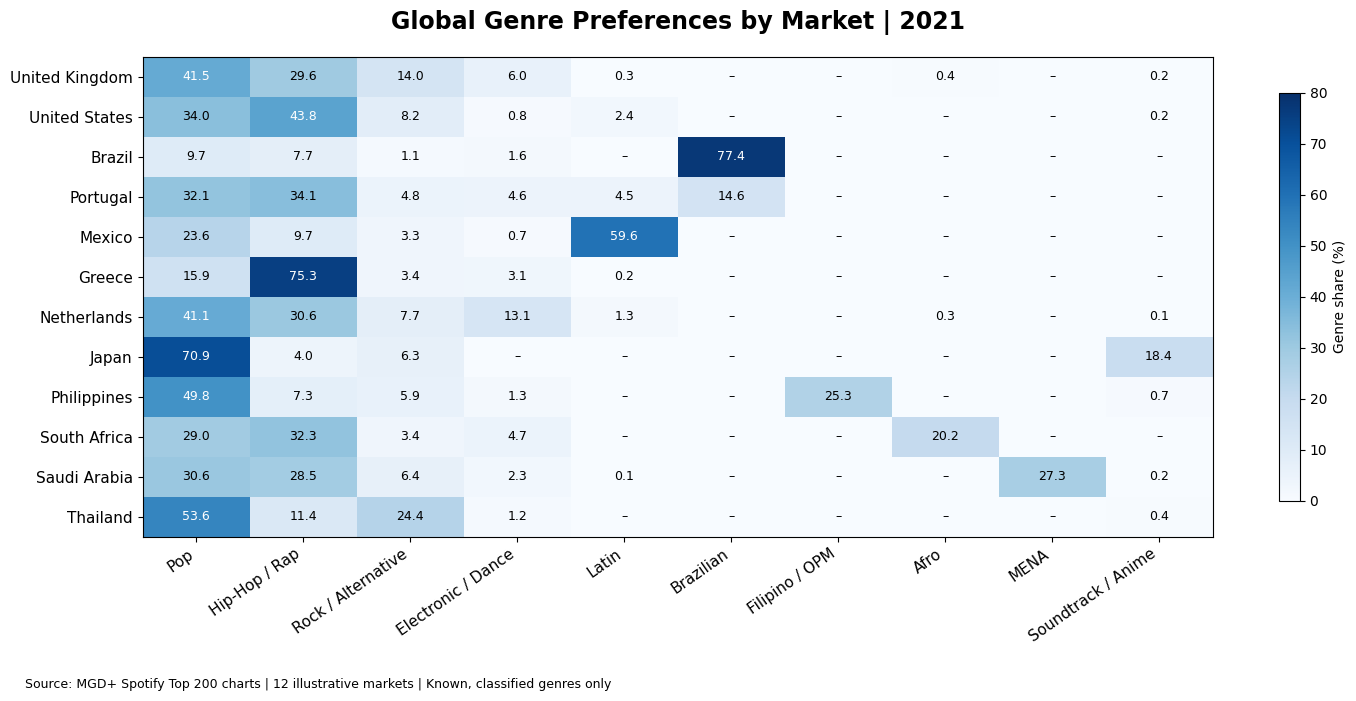

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

genre_data = pd.read_csv(
    "/content/project4_outputs/03_market_genre_share_2021.csv"
)

# Select representative international markets
markets = {
    "gb": "United Kingdom",
    "us": "United States",
    "br": "Brazil",
    "pt": "Portugal",
    "mx": "Mexico",
    "gr": "Greece",
    "nl": "Netherlands",
    "jp": "Japan",
    "ph": "Philippines",
    "za": "South Africa",
    "sa": "Saudi Arabia",
    "th": "Thailand"
}

genres = [
    "Pop",
    "Hip-Hop / Rap",
    "Rock / Alternative",
    "Electronic / Dance",
    "Latin",
    "Brazilian",
    "Filipino / OPM",
    "Afro",
    "MENA",
    "Soundtrack / Anime"
]

# Convert market-level genre shares to percentages
heatmap = (
    genre_data.pivot(
        index="market",
        columns="genre_family",
        values="genre_share"
    )
    .reindex(index=list(markets), columns=genres)
    .fillna(0) * 100
)

fig, ax = plt.subplots(figsize=(15, 7))

img = ax.imshow(
    heatmap.values,
    aspect="auto",
    cmap="Blues",
    vmin=0,
    vmax=80
)

ax.set_xticks(range(len(genres)))
ax.set_xticklabels(genres, rotation=35, ha="right", fontsize=11)

ax.set_yticks(range(len(markets)))
ax.set_yticklabels(list(markets.values()))
ax.tick_params(axis="y", labelsize=11)

# Display percentages inside the heatmap
for i in range(len(markets)):
    for j in range(len(genres)):
        value = heatmap.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.1f}" if value >= 0.1 else "–",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if value > 40 else "black"
        )

colorbar = fig.colorbar(img, ax=ax, shrink=0.85)
colorbar.set_label("Genre share (%)")

ax.set_title(
    "Global Genre Preferences by Market | 2021",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("")
ax.set_ylabel("")

fig.text(
    0.02, 0.01,
    "Source: MGD+ Spotify Top 200 charts | "
    "12 illustrative markets | Known, classified genres only",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(
    "/content/project4_outputs/Figure_02_Genre_Market_Heatmap.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

clusters = pd.read_csv(
    "/content/project4_outputs/08_market_clusters_k5.csv"
)

# Average genre shares across markets in each cluster
genre_cols = [
    col for col in clusters.columns
    if col not in ["market", "cluster"]
]

profiles = (
    clusters.groupby("cluster")[genre_cols]
    .mean() * 100
)

cluster_sizes = clusters.groupby("cluster").size()

print("Markets analyzed:", len(clusters))
print("Number of clusters:", len(cluster_sizes))
display(cluster_sizes)


Markets analyzed: 65
Number of clusters: 5


,0
cluster,
0,10
1,29
2,16
3,9
4,1


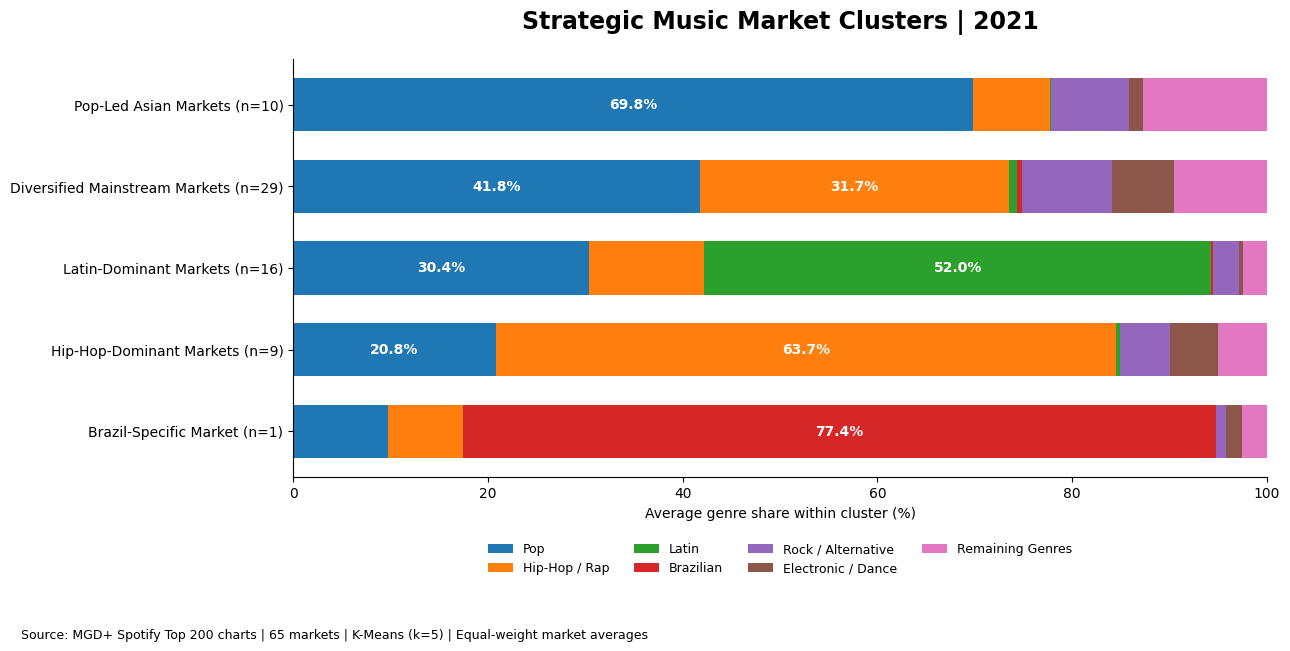

In [ ]:

# Highlight the main genre families
key_genres = [
    "Pop",
    "Hip-Hop / Rap",
    "Latin",
    "Brazilian",
    "Rock / Alternative",
    "Electronic / Dance"
]

chart_data = profiles[key_genres].copy()

chart_data["Remaining Genres"] = (
    100 - chart_data.sum(axis=1)
).clip(lower=0)

cluster_names = {
    0: "Pop-Led Asian Markets",
    1: "Diversified Mainstream Markets",
    2: "Latin-Dominant Markets",
    3: "Hip-Hop-Dominant Markets",
    4: "Brazil-Specific Market"
}

labels = [
    f"{cluster_names[c]} (n={cluster_sizes[c]})"
    for c in chart_data.index
]

fig, ax = plt.subplots(figsize=(13, 6.5))

left = np.zeros(len(chart_data))
y = np.arange(len(chart_data))

for genre in chart_data.columns:

    values = chart_data[genre].to_numpy()

    ax.barh(
        y,
        values,
        left=left,
        height=0.65,
        label=genre
    )

    # Label larger genre segments
    for i, value in enumerate(values):
        if value >= 15:
            ax.text(
                left[i] + value / 2,
                i,
                f"{value:.1f}%",
                ha="center",
                va="center",
                color="white",
                fontweight="bold",
                fontsize=10
            )

    left += values

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=10)
ax.invert_yaxis()

ax.set_xlim(0, 100)
ax.set_xlabel("Average genre share within cluster (%)")
ax.set_ylabel("")

ax.set_title(
    "Strategic Music Market Clusters | 2021",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=4,
    frameon=False,
    fontsize=9
)

fig.text(
    0.02, 0.01,
    "Source: MGD+ Spotify Top 200 charts | "
    "65 markets | K-Means (k=5) | "
    "Equal-weight market averages",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

plt.savefig(
    "/content/project4_outputs/Figure_03_Market_Clusters.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()


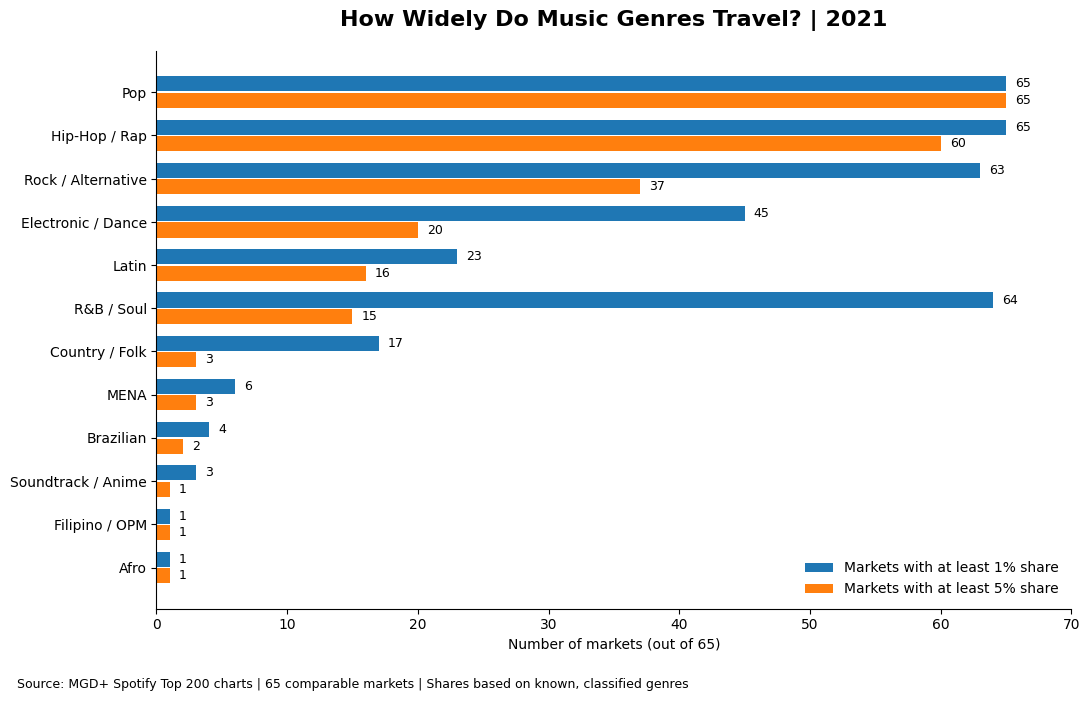

In [ ]:

# Use the 2021 market-genre data from Visualization 2
reach = (
    genre_data.groupby("genre_family")
    .agg(
        markets_above_1pct=(
            "genre_share", lambda x: (x >= 0.01).sum()
        ),
        markets_above_5pct=(
            "genre_share", lambda x: (x >= 0.05).sum()
        )
    )
)

selected_genres = [
    "Pop", "Hip-Hop / Rap", "Rock / Alternative",
    "Electronic / Dance", "R&B / Soul", "Latin",
    "Country / Folk", "MENA", "Brazilian",
    "Soundtrack / Anime", "Filipino / OPM", "Afro"
]

plot_data = (
    reach.loc[selected_genres]
    .sort_values(
        ["markets_above_5pct", "markets_above_1pct"],
        ascending=False
    )
)

fig, ax = plt.subplots(figsize=(11, 7))

y = np.arange(len(plot_data))

ax.barh(
    y - 0.19,
    plot_data["markets_above_1pct"],
    height=0.35,
    label="Markets with at least 1% share"
)

ax.barh(
    y + 0.19,
    plot_data["markets_above_5pct"],
    height=0.35,
    label="Markets with at least 5% share"
)

for i, (_, row) in enumerate(plot_data.iterrows()):
    for offset, col in [
        (-0.19, "markets_above_1pct"),
        (0.19, "markets_above_5pct")
    ]:
        ax.text(
            row[col] + 0.7,
            i + offset,
            str(int(row[col])),
            va="center",
            fontsize=9
        )

ax.set_yticks(y)
ax.set_yticklabels(plot_data.index)
ax.invert_yaxis()

ax.set_xlim(0, 70)
ax.set_xlabel("Number of markets (out of 65)")
ax.set_title(
    "How Widely Do Music Genres Travel? | 2021",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.legend(
    loc="lower right",
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.02, 0.01,
    "Source: MGD+ Spotify Top 200 charts | "
    "65 comparable markets | "
    "Shares based on known, classified genres",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

plt.savefig(
    "/content/project4_outputs/Figure_04_Genre_Portability.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()


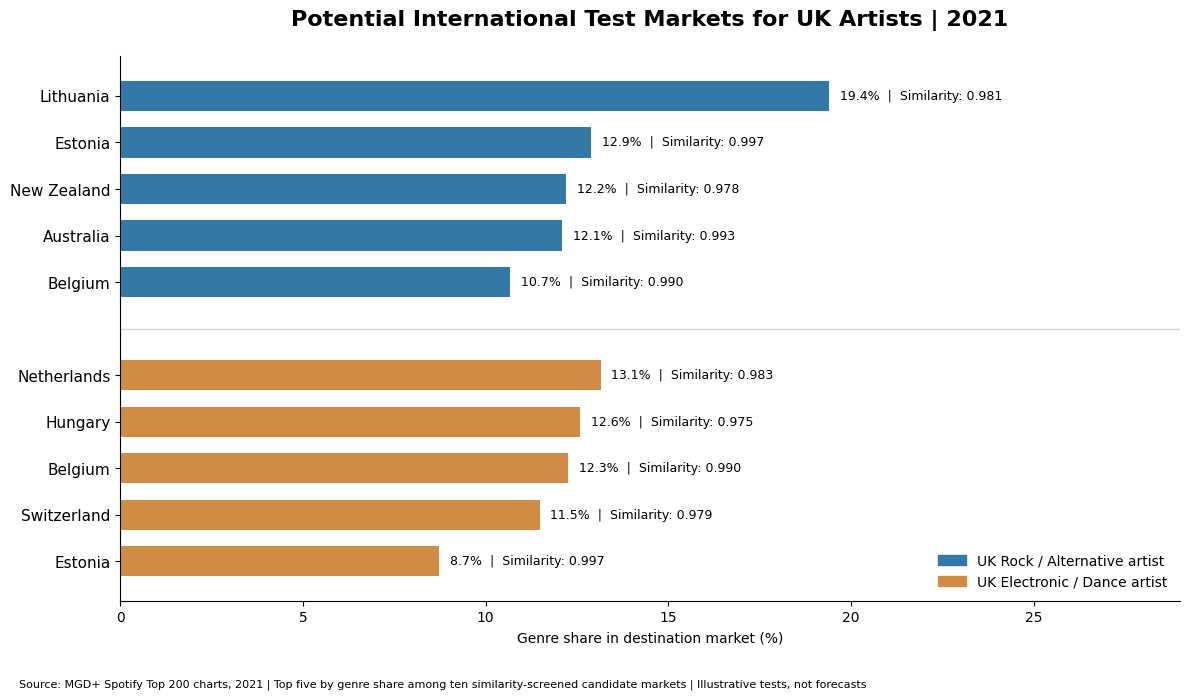

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load finalized UK expansion candidates
rock = pd.read_csv(
    "/content/project4_outputs/09_uk_rock_test_markets.csv"
)

electronic = pd.read_csv(
    "/content/project4_outputs/10_uk_electronic_test_markets.csv"
)

# Within each pre-screened candidate list,
# select the five strongest genre-share markets
rock_top = rock.nlargest(5, "genre_share_pct").copy()
rock_top["scenario"] = "Rock / Alternative"

electronic_top = electronic.nlargest(
    5, "genre_share_pct"
).copy()
electronic_top["scenario"] = "Electronic / Dance"

candidates = pd.concat(
    [rock_top, electronic_top],
    ignore_index=True
)

country_names = {
    "lt": "Lithuania",
    "ee": "Estonia",
    "nz": "New Zealand",
    "au": "Australia",
    "be": "Belgium",
    "nl": "Netherlands",
    "hu": "Hungary",
    "ch": "Switzerland"
}

candidates["country"] = (
    candidates["market"]
    .map(country_names)
    .fillna(candidates["market"].str.upper())
)

# Leave a small gap between the two artist scenarios
y = list(range(5)) + list(range(6, 11))

colors = [
    "#3478A7" if genre == "Rock / Alternative"
    else "#D28B45"
    for genre in candidates["scenario"]
]

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    y,
    candidates["genre_share_pct"],
    color=colors,
    height=0.65
)

ax.set_yticks(y)
ax.set_yticklabels(candidates["country"], fontsize=11)
ax.invert_yaxis()

# Display genre share and overall market similarity
for pos, (_, row) in zip(y, candidates.iterrows()):
    ax.text(
        row["genre_share_pct"] + 0.3,
        pos,
        f'{row["genre_share_pct"]:.1f}%  |  '
        f'Similarity: {row["similarity"]:.3f}',
        va="center",
        fontsize=9
    )

ax.axhline(5, color="lightgray", linewidth=1)

ax.set_xlim(0, 29)
ax.set_xlabel("Genre share in destination market (%)")
ax.set_ylabel("")

ax.set_title(
    "Potential International Test Markets for UK Artists | 2021",
    fontsize=16,
    fontweight="bold",
    pad=22
)

from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(color="#3478A7", label="UK Rock / Alternative artist"),
        Patch(color="#D28B45", label="UK Electronic / Dance artist")
    ],
    loc="lower right",
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.02, 0.01,
    "Source: MGD+ Spotify Top 200 charts, 2021 | "
    "Top five by genre share among ten similarity-screened "
    "candidate markets | Illustrative tests, not forecasts",
    fontsize=8
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(
    "/content/project4_outputs/Figure_05_International_Expansion.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()


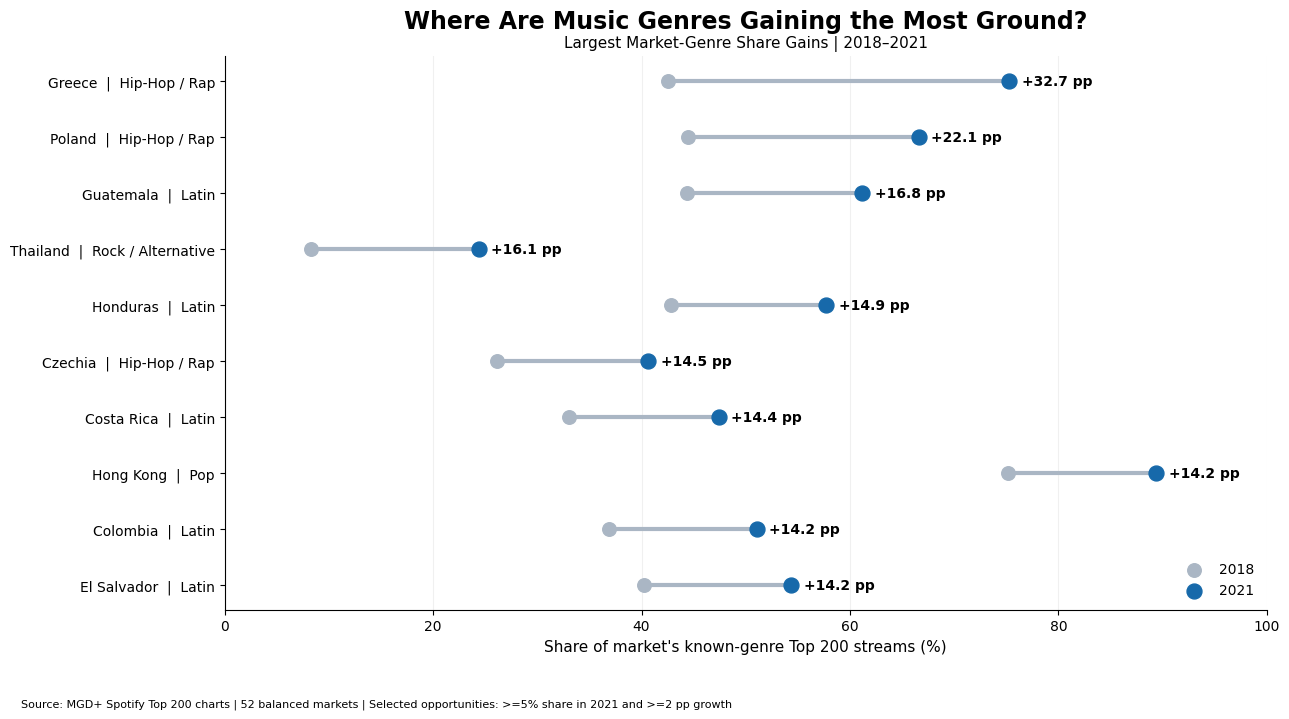

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the finalized growth opportunities
growth = pd.read_csv(
    "/content/project4_outputs/06_market_genre_growth_opportunities.csv"
)

# Top 10 by percentage-point growth
top_growth = (
    growth.sort_values("change_pp", ascending=False)
    .head(10)
    .copy()
)

# Convert country codes into readable names
country_names = {
    "gr": "Greece",
    "pl": "Poland",
    "gt": "Guatemala",
    "th": "Thailand",
    "hn": "Honduras",
    "cz": "Czechia",
    "cr": "Costa Rica",
    "hk": "Hong Kong",
    "co": "Colombia",
    "sv": "El Salvador"
}

top_growth["country"] = (
    top_growth["market"]
    .map(country_names)
    .fillna(top_growth["market"].str.upper())
)

top_growth["label"] = (
    top_growth["country"]
    + "  |  "
    + top_growth["genre_family"]
)

fig, ax = plt.subplots(figsize=(13, 7.5))

y = np.arange(len(top_growth))

# Draw growth connecting lines
for i, row in top_growth.iterrows():
    pass

for pos, (_, row) in enumerate(top_growth.iterrows()):

    start = row["share_2018_pct"]
    end = row["share_2021_pct"]

    ax.plot(
        [start, end],
        [pos, pos],
        color="#AAB6C4",
        linewidth=3,
        zorder=1
    )

# 2018 starting values
ax.scatter(
    top_growth["share_2018_pct"],
    y,
    s=95,
    color="#AAB6C4",
    label="2018",
    zorder=3
)

# 2021 ending values
ax.scatter(
    top_growth["share_2021_pct"],
    y,
    s=115,
    color="#1769AA",
    label="2021",
    zorder=4
)

# Show growth next to the ending values
for pos, (_, row) in enumerate(top_growth.iterrows()):
    ax.text(
        row["share_2021_pct"] + 1.2,
        pos,
        f'+{row["change_pp"]:.1f} pp',
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_yticks(y)
ax.set_yticklabels(top_growth["label"], fontsize=10)
ax.invert_yaxis()

ax.set_xlim(
    0,
    min(100, top_growth["share_2021_pct"].max() + 13)
)

ax.set_xlabel(
    "Share of market's known-genre Top 200 streams (%)",
    fontsize=11
)

ax.set_title(
    "Where Are Music Genres Gaining the Most Ground?",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.text(
    0.5, 1.015,
    "Largest Market-Genre Share Gains | 2018–2021",
    transform=ax.transAxes,
    ha="center",
    fontsize=11
)

ax.legend(
    loc="lower right",
    frameon=False
)

ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.text(
    0.02, 0.01,
    "Source: MGD+ Spotify Top 200 charts | "
    "52 balanced markets | "
    "Selected opportunities: >=5% share in 2021 "
    "and >=2 pp growth",
    fontsize=8
)

plt.tight_layout(rect=[0, 0.06, 1, 0.96])

plt.savefig(
    "/content/project4_outputs/Figure_06_Growth_Opportunities.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()
